## Exercícios — Simulação de Monte Carlo

Em todos os exercícios, utilize $n=10^4$ simulações independentes, salvo indicação contrária.

### Exercício 1 — Estimação de integrais

Considere a integral

$$
I=\int_0^1 e^{-x^2}\,dx.
$$

Utilizando $X\sim U(0,1)$, estime $I$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.



### Exercício 2 — Estimação de probabilidades

Considere $X\sim N(0,1)$ e a probabilidade

$$
p=P(X>1).
$$

Estime $p$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.

### Exercício 3 — Estimação de $\pi$

Considere $(X,Y)$ uniformemente distribuído em $[0,1]^2$ e o evento

$$
A=\{X^2+Y^2\leq 1\}.
$$

Utilize Monte Carlo para estimar $\pi$, calcule a variância do estimador e construa um intervalo de confiança de 95%.

### Exercício 4 — Estimação de média e variância

Considere $X\sim U(0,1)$.

Estime $E[X]$ e $\operatorname{Var}(X)$ por Monte Carlo. Calcule a variância do estimador da média e construa um intervalo de confiança de 95% para $E[X]$.

### Exercício 5 — Integração em duas dimensões

Considere a integral

$$
I=\int_0^1\int_0^1 e^{-(x^2+y^2)}\,dx\,dy.
$$

Utilizando $(X,Y)\sim U([0,1]^2)$, estime $I$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.

### Exercício 6 — Esperança de uma função

Considere $X\sim \operatorname{Exp}(1)$ e

$$
\mu=E[e^{-X}].
$$

Estime $\mu$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%. Compare com o valor teórico.

### Exercício 7 — Integral imprópria

Considere a integral

$$
I=\int_0^\infty \frac{e^{-x}}{1+x}\,dx.
$$

Utilizando $X\sim \operatorname{Exp}(1)$, estime $I$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.

### Exercício 8 — Integral oscilatória

Considere a integral truncada

$$
I_L=\int_0^L \frac{\sin(x)}{x}\,dx,
\qquad L=20.
$$

Utilizando $X\sim U(0,L)$, estime $I_L$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%. Compare com $\pi/2$.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
n = 10**4
sucessos = 0

### Exercício 1 — Estimação de integrais

Considere a integral

$$
I=\int_0^1 e^{-x^2}\,dx.
$$

Utilizando $X\sim U(0,1)$, estime $I$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.

dicas criar a amostra

utilizar as bibliotecas no python

In [3]:
#Exercicio 1
hope = 0
amostra = []
for i in range(n):
  u = np.random.uniform()
  hope = np.exp(-u**2)
  amostra.append(hope)
new_hope = np.sum(amostra)/n
var = np.var(amostra)
media = np.mean(amostra)
print(f"A integral tem vale aproximadamente {new_hope}")
print(f"A variancia é {np.var(amostra)}")
print(f"O desvio padrão é {np.sqrt(np.var(amostra))}")

#Calculando o intervalo de confiança
ic_min, ic_max = media-1.96*np.sqrt(var/n), media+1.96*np.sqrt(var/n)
print(f"O intervalo de confiança varia entre [{ic_min}], [{ic_max}]")

A integral tem vale aproximadamente 0.7428229519996002
A variancia é 0.04061251725237459
O desvio padrão é 0.20152547544262137
O intervalo de confiança varia entre [0.7388730526809248], [0.7467728513182756]


### Exercício 2 — Estimação de probabilidades

Considere $X\sim N(0,1)$ e a probabilidade

$$
p=P(X>1).
$$

Estime $p$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.

In [4]:
def f(x):
  return 2*np.exp((-x**2)/2)/np.sqrt(2*np.pi)

In [5]:
def g(x):
  return np.exp(-x)

O p vale 0.1612
A variancia vale 1.0020620334633714
O IC de 95% vai de [0.14157980247868823 ; 0.1808201975213118]


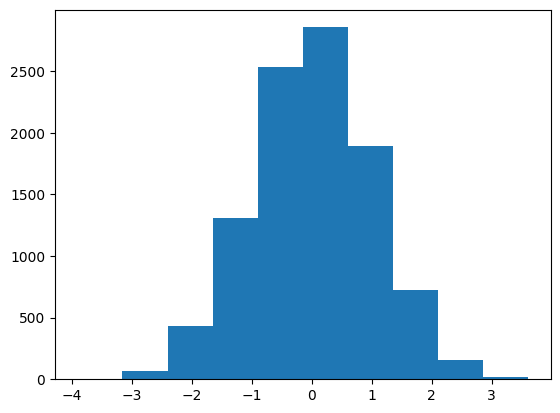

In [6]:
#Gerando a normal (0,1)
c = f(1)/g(1)
c = np.sqrt(2*np.e/np.pi)
amostra = []
p = 0
for i in range(n):
  u = np.random.uniform()
  y = -np.log(u) #Gerando a exponencial
  U = np.random.uniform()
  while U*c*g(y) > f(y):
    u = np.random.uniform()
    y = -np.log(u) #Gerando a exponencial
    U = np.random.uniform()
  moeda = np.random.uniform()
  if moeda < 0.5:
    amostra.append(-y)
  else:
    amostra.append(y)
  if y > 1 and moeda > 0.5:
    p += 1
plt.hist(amostra)
#Gerando monte carlo a partir da normal (0,1)
media = np.mean(amostra)
p_fin = p/n
var = np.var(amostra) #Variancia
ic_min ,ic_max = p_fin-1.96*np.sqrt(var/n), p_fin+1.96*np.sqrt(var/n)
print(f"O p vale {p_fin}")
print(f"A variancia vale {var}")
print(f"O IC de 95% vai de [{ic_min} ; {ic_max}]")

### Exercício 3 — Estimação de $\pi$

Considere $(X,Y)$ uniformemente distribuído em $[0,1]^2$ e o evento

$$
A=\{X^2+Y^2\leq 1\}.
$$

Utilize Monte Carlo para estimar $\pi$, calcule a variância do estimador e construa um intervalo de confiança de 95%.


In [7]:
amostra = []
amostra_estimador = []
for i in range(n):

  x = np.random.uniform()
  y = np.random.uniform()
  if x**2 + y**2 <= 1: #Pertence a pi
    amostra.append(1)
  else:
    amostra.append(0)

pi = 4*np.sum(amostra)/n
var = np.var(amostra)
media = np.mean(amostra)

ic_min , ic_max = pi-1.96*np.sqrt(var/n), pi+1.96*np.sqrt(var/n)
print(f"O valor de pi estimado é {pi}")
print(f"O valor da variancia do estimador é {var}")
print(f"O IC de 95% vai de [{ic_min} ; {ic_max}]")
print(media)

O valor de pi estimado é 3.1584
O valor da variancia do estimador é 0.16613184
O IC de 95% vai de [3.150411182336891 ; 3.1663888176631088]
0.7896


### Exercício 4 — Estimação de média e variância

Considere $X\sim U(0,1)$.

Estime $E[X]$ e $\operatorname{Var}(X)$ por Monte Carlo. Calcule a variância do estimador da média e construa um intervalo de confiança de 95% para $E[X]$.

In [8]:
amostra = []
n = 10**4
for i in range(n):
  u = np.random.uniform()
  amostra.append(u)

mi = np.sum(amostra)/n
sigma_2 = np.var(amostra)
ic_min, ic_max = mi-1.96*np.sqrt(sigma_2/n), mi+1.96*np.sqrt(sigma_2/n)
print(f"O valor da media do estimador é {mi}")
print(f"O valor da variancia do estimador é {sigma_2}")
print(f"O IC de 95% vai de [{ic_min} ; {ic_max}]")

O valor da media do estimador é 0.5010417982529958
O valor da variancia do estimador é 0.0842328161508324
O IC de 95% vai de [0.4953533117537146 ; 0.5067302847522769]


### Exercício 5 — Integração em duas dimensões

Considere a integral

$$
I=\int_0^1\int_0^1 e^{-(x^2+y^2)}\,dx\,dy.
$$

Utilizando $(X,Y)\sim U([0,1]^2)$, estime $I$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.


In [9]:
n = 10**4
amostra_x = []
amostra_y = []
amostra_T = []
for i in range(n):
  x = np.random.uniform()
  y = np.random.uniform()
  amostra_T.append(np.exp(-((x**2)+(y**2))))
print(np.mean(amostra_T))
print(f"A integral resulta em ")

0.554618651390798
A integral resulta em 



### Exercício 6 — Esperança de uma função

Considere $X\sim \operatorname{Exp}(1)$ e

$$
\mu=E[e^{-X}].
$$

Estime $\mu$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%. Compare com o valor teórico.

In [10]:
amostra = []
lamb = 1
n = 10000
for i in range(n):
  u = np.random.uniform()
  y = -np.log(u)/lamb
  amostra.append(np.exp(-y))

mi = np.mean(amostra)
var = np.var(amostra)
ic_min, ic_max = mi-1.96*np.sqrt(var/n), mi+1.96*np.sqrt(var/n)
print(f"O valor de mi {mi}")
print(f"A variância é {var}")
print(f"O IC de 95% varia entre [{ic_min, ic_max}]")

O valor de mi 0.4999958202645274
A variância é 0.08308624353115965
O IC de 95% varia entre [(np.float64(0.4943461821066512), np.float64(0.5056454584224035))]


### Exercício 7 — Integral imprópria

Considere a integral

$$
I=\int_0^\infty \frac{e^{-x}}{1+x}\,dx.
$$

Utilizando $X\sim \operatorname{Exp}(1)$, estime $I$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%.

In [21]:
n = 10000
amostra = []
lamb= 1
for i in range(n):
  u = np.random.uniform()
  y = -np.log(u)/lamb
  amostra.append((y))


mi = np.mean(1/(1 + np.array(amostra)))
var = np.var(1/(1 + np.array(amostra)))

ic_min, ic_max = mi-1.96*np.sqrt(var/n), mi+1.96*np.sqrt(var/n)

print(f"{mi} integral estimada")
print(f"A variância é {var}")
print(f"({ic_min} ; {ic_max}) I.C. 95%")

0.5962066749254533 integral estimada
A variância é 0.04812121258188211
(0.5919071115725701 ; 0.6005062382783365) I.C. 95%


### Exercício 8 — Integral oscilatória

Considere a integral truncada

$$
I_L=\int_0^L \frac{\sin(x)}{x}\,dx,
\qquad L=20.
$$

Utilizando $X\sim U(0,L)$, estime $I_L$ por Monte Carlo, calcule a variância do estimador e construa um intervalo de confiança de 95%. Compare com $\pi/2$.

In [22]:
L = 20
N = 1000000
u = np.random.uniform(size=N)*L


g = L * np.sin(u)/ u
mi = np.mean(g)
var = np.var(g)

ic_min, ic_max = mi-1.96*np.sqrt(var/n), mi+1.96*np.sqrt(var/n)

print(f"{mi} integral estimada")
print(f"A variância é {var}")
print(f"({ic_min} ; {ic_max}) I.C. 95%")
print(f"{np.pi/2} é o valor de pi/2")


1.545395115856472 integral estimada
A variância é 28.52575385755038
(1.440712483094793 ; 1.650077748618151) I.C. 95%
1.5707963267948966 é o valor de pi/2
